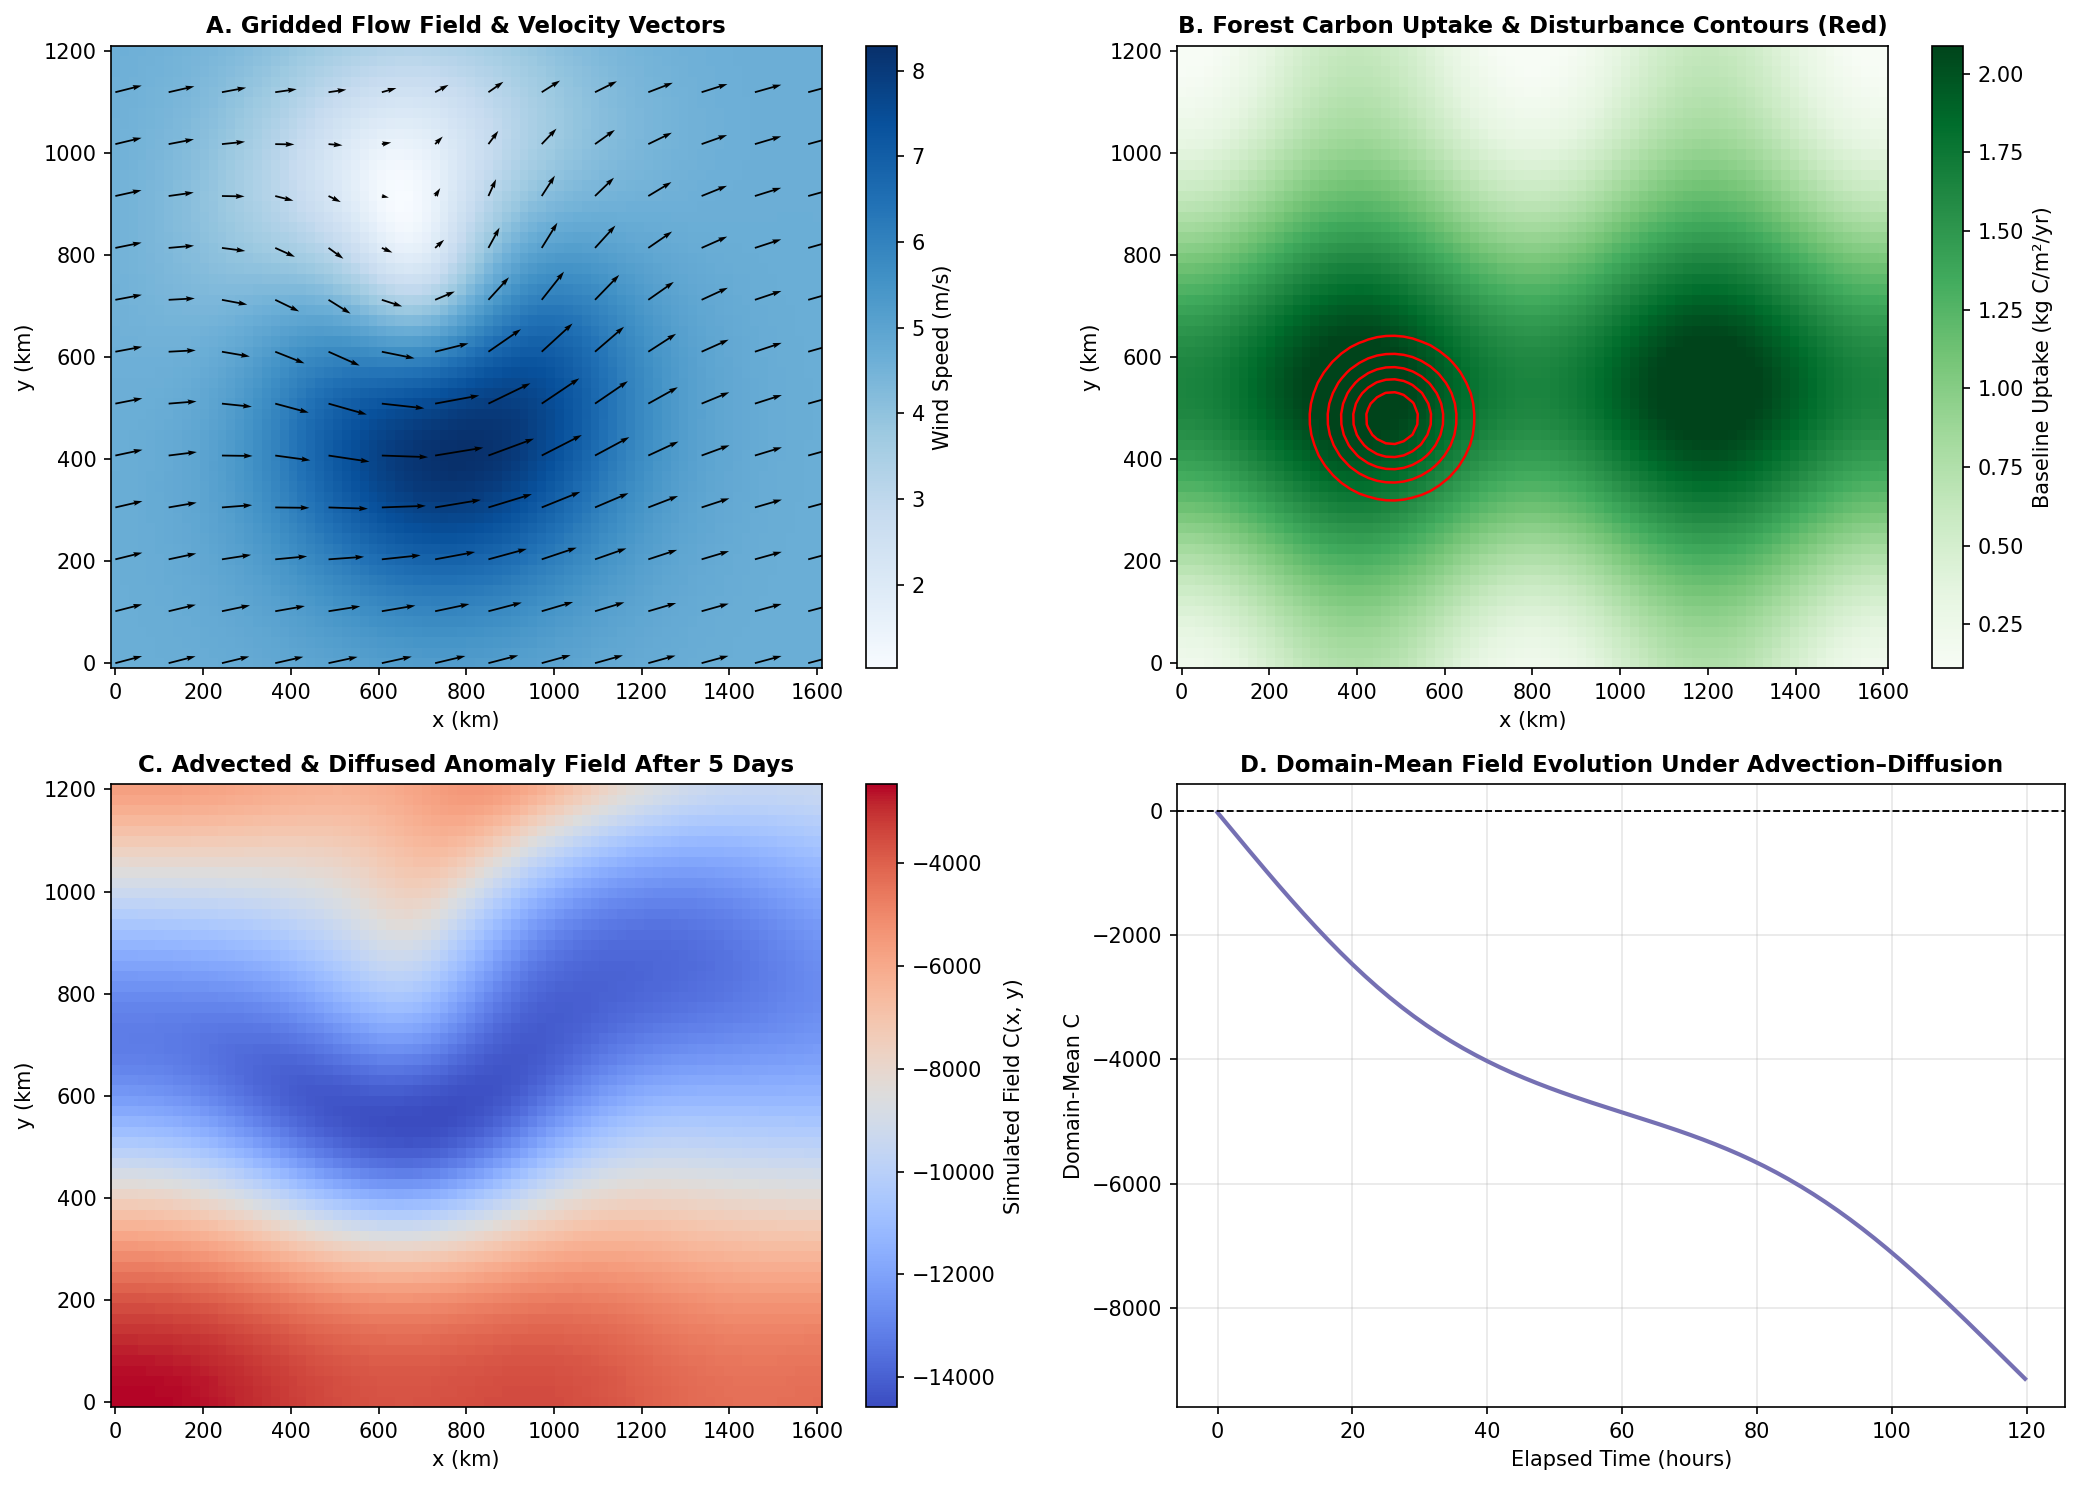

Grid resolution: dx = 20.3 km, dy = 20.3 km | Time step dt = 819.7 s (527 steps)
Max wind speed: 8.30 m/s
Max relative vorticity magnitude: 4.59e-05 s^-1
Final domain-mean field C: -9135.0154


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ==============================================================================
# 1. LOAD OR BUILD GRIDDED DATASET (FLOW FIELD + FOREST CARBON UPTAKE/DISTURBANCE)
# ==============================================================================
# We construct a 2D spatial domain (x, y in km) with a multi-scale wind/flow field
# (u, v in m/s), forest uptake rate (kg C / m^2 / yr), and disturbance plumes.
# You can also inspect or swap in xarray datasets for real gridded fields.

nx, ny = 80, 60
Lx, Ly = 1600.0e3, 1200.0e3  # Domain size in meters (1600 km x 1200 km)
x = np.linspace(0.0, Lx, nx)
y = np.linspace(0.0, Ly, ny)
dx = x[1] - x[0]
dy = y[1] - y[0]
X, Y = np.meshgrid(x, y, indexing="ij")  # Shape: (nx, ny)

# Gridded 2D wind/transport velocity field (u, v) in m/s:
# Mean prevailing wind + mesoscale circulation eddy (vortical flow)
cx, cy = 0.45 * Lx, 0.55 * Ly
r2 = (X - cx) ** 2 + (Y - cy) ** 2
eddy_envelope = np.exp(-r2 / (2.0 * (260.0e3) ** 2))

# Streamfunction psi -> u = -d(psi)/dy, v = d(psi)/dx (divergence-free eddy component)
u_mean = 4.5  # m/s prevailing wind in +x
v_mean = 1.2  # m/s prevailing wind in +y
vorticity_amp = 6.0  # m/s peak swirling speed

u = u_mean - vorticity_amp * ((Y - cy) / 260.0e3) * eddy_envelope
v = v_mean + vorticity_amp * ((X - cx) / 260.0e3) * eddy_envelope

# Forest cover fraction & baseline carbon uptake (positive = uptake by forest)
forest_cover = np.clip(
    0.75 * np.exp(-((Y - 0.45 * Ly) / (380.0e3)) ** 2)
    + 0.25 * np.sin(2.0 * np.pi * X / Lx) ** 2,
    0.05,
    0.95,
)
base_uptake_rate = 2.2 * forest_cover  # kg C / m^2 / yr equivalent source/sink scale

# Localized forest disturbance plume (e.g., wildfire/drought releasing carbon)
disturbance_plume = 1.8 * np.exp(
    -(((X - 0.30 * Lx) / (140.0e3)) ** 2 + ((Y - 0.40 * Ly) / (120.0e3)) ** 2)
)

# Package spatial fields into an xarray.Dataset for clean gridded analysis
ds_grid = xr.Dataset(
    {
        "u": (("x", "y"), u),
        "v": (("x", "y"), v),
        "forest_cover": (("x", "y"), forest_cover),
        "base_uptake_rate": (("x", "y"), base_uptake_rate),
        "disturbance_plume": (("x", "y"), disturbance_plume),
    },
    coords={"x": x / 1e3, "y": y / 1e3},  # Coordinates in km
)
ds_grid["speed"] = np.hypot(ds_grid["u"], ds_grid["v"])

# Compute discrete spatial gradients (du/dx, dv/dy, du/dy, dv/dx) on the grid
du_dx = np.gradient(u, dx, axis=0)
dv_dy = np.gradient(v, dy, axis=1)
du_dy = np.gradient(u, dy, axis=1)
dv_dx = np.gradient(v, dx, axis=0)

divergence = du_dx + dv_dy          # Horizontal divergence (1/s)
relative_vorticity = dv_dx - du_dy  # Vertical component of vorticity (1/s)
ds_grid["divergence"] = (("x", "y"), divergence)
ds_grid["vorticity"] = (("x", "y"), relative_vorticity)

# ==============================================================================
# 2. SOLVE 2D ADVECTION-DIFFUSION-UPTAKE PDE WITH STABILITY (CFL) CHECK
#    dC/dt + u * dC/dx + v * dC/dy = kappa * (d2C/dx2 + d2C/dy2) + S(x, y, t)
# ==============================================================================
kappa = 2.5e4  # Turbulent eddy diffusivity (m^2 / s)

u_max = float(np.max(np.abs(u))) + 1e-9
v_max = float(np.max(np.abs(v))) + 1e-9

# CFL stability limits for explicit advection and explicit 2D diffusion
dt_adv = 0.4 * min(dx / u_max, dy / v_max)
dt_diff = 0.2 * (min(dx, dy) ** 2) / (4.0 * kappa + 1e-9)
dt = min(dt_adv, dt_diff, 1800.0)  # Cap time step at 30 minutes (1800 s)

total_simulation_time = 24.0 * 3600.0 * 5.0  # 5-day simulation in seconds
n_steps = int(np.ceil(total_simulation_time / dt))
dt = total_simulation_time / n_steps

# Tracer / carbon flux anomaly field C(x, y, t) (arbitrary concentration/flux units)
C = np.zeros((nx, ny), dtype=np.float64)

# Net source/sink field S(x, y, t):
# - Forest uptake acts as a negative source (drawdown) over vegetated areas
# - Disturbance plume acts as a positive emission pulse during the first 2 days
sec_per_year = 365.25 * 24.0 * 3600.0
uptake_sink_rate = -(base_uptake_rate / sec_per_year) * 1e6  # Scaled flux units/s

history_times_hr = []
history_mean_C = []
history_uptake_drawdown = []

for step in range(n_steps):
    t_curr = step * dt
    t_days = t_curr / 86400.0

    # Disturbance active mainly during days 0.5 to 2.5, with seasonal modulation
    disturbance_active = np.exp(-0.5 * ((t_days - 1.5) / 0.7) ** 2)
    seasonal_pulse = 0.7 + 0.3 * np.cos(2.0 * np.pi * t_days / 5.0)
    source_term = (
        uptake_sink_rate * seasonal_pulse
        + (disturbance_plume / sec_per_year) * 1e6 * disturbance_active
    )

    # First-order upwind derivatives for advection (stable for u >= 0, v >= 0;
    # written generally for both signs of u and v)
    dC_dx_bwd = np.zeros_like(C)
    dC_dx_fwd = np.zeros_like(C)
    dC_dy_bwd = np.zeros_like(C)
    dC_dy_fwd = np.zeros_like(C)

    dC_dx_bwd[1:, :] = (C[1:, :] - C[:-1, :]) / dx
    dC_dx_fwd[:-1, :] = (C[1:, :] - C[:-1, :]) / dx

    dC_dy_bwd[:, 1:] = (C[:, 1:] - C[:, :-1]) / dy
    dC_dy_fwd[:, :-1] = (C[:, 1:] - C[:, :-1]) / dy

    adv_x = np.where(u >= 0.0, u * dC_dx_bwd, u * dC_dx_fwd)
    adv_y = np.where(v >= 0.0, v * dC_dy_bwd, v * dC_dy_fwd)

    # Central-difference 2D Laplacian for diffusion (zero-gradient boundary padding)
    C_pad = np.pad(C, pad_width=1, mode="edge")
    d2C_dx2 = (C_pad[2:, 1:-1] - 2.0 * C_pad[1:-1, 1:-1] + C_pad[:-2, 1:-1]) / (dx ** 2)
    d2C_dy2 = (C_pad[1:-1, 2:] - 2.0 * C_pad[1:-1, 1:-1] + C_pad[1:-1, :-2]) / (dy ** 2)
    diff_term = kappa * (d2C_dx2 + d2C_dy2)

    # Explicit Euler update
    C = C + dt * (-adv_x - adv_y + diff_term + source_term)

    if step % max(1, n_steps // 120) == 0 or step == n_steps - 1:
        history_times_hr.append(t_curr / 3600.0)
        history_mean_C.append(float(np.mean(C)))
        history_uptake_drawdown.append(float(np.mean(uptake_sink_rate * seasonal_pulse) * 3600.0))

# ==============================================================================
# 3. VISUALIZATION & DIAGNOSTICS
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# Panel A: Wind/Flow Speed + Quiver Vectors + Vorticity Contours
skip_x = slice(0, nx, 6)
skip_y = slice(0, ny, 5)
im_a = axes[0, 0].pcolormesh(
    ds_grid["x"].values,
    ds_grid["y"].values,
    ds_grid["speed"].values.T,
    cmap="Blues",
    shading="auto",
)
axes[0, 0].quiver(
    ds_grid["x"].values[skip_x],
    ds_grid["y"].values[skip_y],
    ds_grid["u"].values[skip_x, skip_y].T,
    ds_grid["v"].values[skip_x, skip_y].T,
    color="black",
    scale=120,
    width=0.0025,
)
plt.colorbar(im_a, ax=axes[0, 0], label="Wind Speed (m/s)")
axes[0, 0].set_title("A. Gridded Flow Field & Velocity Vectors", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("x (km)")
axes[0, 0].set_ylabel("y (km)")

# Panel B: Forest Uptake Rate & Disturbance Plume
im_b = axes[0, 1].pcolormesh(
    ds_grid["x"].values,
    ds_grid["y"].values,
    ds_grid["base_uptake_rate"].values.T,
    cmap="Greens",
    shading="auto",
)
axes[0, 1].contour(
    ds_grid["x"].values,
    ds_grid["y"].values,
    ds_grid["disturbance_plume"].values.T,
    levels=5,
    colors="red",
    linewidths=1.2,
)
plt.colorbar(im_b, ax=axes[0, 1], label="Baseline Uptake (kg C/m²/yr)")
axes[0, 1].set_title("B. Forest Carbon Uptake & Disturbance Contours (Red)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("x (km)")
axes[0, 1].set_ylabel("y (km)")

# Panel C: Final Advected & Diffused Tracer/Carbon Anomaly Field C(x, y, t_final)
im_c = axes[1, 0].pcolormesh(
    ds_grid["x"].values,
    ds_grid["y"].values,
    C.T,
    cmap="coolwarm",
    shading="auto",
)
plt.colorbar(im_c, ax=axes[1, 0], label="Simulated Field C(x, y)")
axes[1, 0].set_title("C. Advected & Diffused Anomaly Field After 5 Days", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("x (km)")
axes[1, 0].set_ylabel("y (km)")

# Panel D: Domain-Mean Evolution Over Time
axes[1, 1].plot(history_times_hr, history_mean_C, color="#7570b3", linewidth=2)
axes[1, 1].axhline(0.0, color="black", linestyle="--", linewidth=0.9)
axes[1, 1].set_title("D. Domain-Mean Field Evolution Under Advection–Diffusion", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Elapsed Time (hours)")
axes[1, 1].set_ylabel("Domain-Mean C")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fluid_advection_diffusion_forest_carbon.png")
plt.show()

print(f"Grid resolution: dx = {dx/1e3:.1f} km, dy = {dy/1e3:.1f} km | Time step dt = {dt:.1f} s ({n_steps} steps)")
print(f"Max wind speed: {float(ds_grid['speed'].max().values):.2f} m/s")
print(f"Max relative vorticity magnitude: {np.max(np.abs(relative_vorticity)):.2e} s^-1")
print(f"Final domain-mean field C: {history_mean_C[-1]:.4f}")